# **02 - Inference Smoketest Pipeline**

## **1. Pipeline Objective**

## **2. Dependency Management**

### **2.1 Package Installation**

In [1]:
!pip install -q transformers accelerate bitsandbytes pandas matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.0 MB/s eta 0:00:00:00:0100:01


### **2.2 Module Imports**

In [2]:
import datetime
import os
import json
import gc
import re
import time
from typing import List, Dict, Any

import pandas as pd
import matplotlib.pyplot as plt

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

### **2.3 Environment Variables**

In [3]:
PROJECT_ROOT: str = '/content/drive/MyDrive/LLMReliability'
DATA_PROCESSED_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'processed')
MODELS_DIR: str = os.path.join(PROJECT_ROOT, 'models')
RESULTS_DIR: str = os.path.join(PROJECT_ROOT, 'results')
MODEL_ID: str = "Qwen/Qwen3-4B-Instruct-2507"

os.environ['HF_HOME'] = MODELS_DIR

print(f"[MODEL] id='{MODEL_ID}' | status=CONFIGURING")

[MODEL] id='Qwen/Qwen3-4B-Instruct-2507' | status=CONFIGURING


## **3. Resource Allocation**

### **3.1 Identity & Access Management (IAM)**

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    
    secrets_path: str = '/content/drive/MyDrive/secrets.json'
    if os.path.exists(secrets_path):
        with open(secrets_path, 'r') as f:
            secrets = json.load(f)
        hf_token = secrets.get("HF_TOKEN", "")
        if hf_token:
            from huggingface_hub import login
            login(token=hf_token)
            print("[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'")
except ImportError:
    print("[ENVIRONMENT] status=LOCAL | component='Google Drive'")

Mounted at /content/drive
[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'


### **3.2 Storage Initialization**

In [5]:
for d in [DATA_PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

## **4. Pilot Data Ingestion**

In [6]:
pilot_path = os.path.join(DATA_PROCESSED_DIR, 'indopref_pilot.parquet')
try:
    df_pilot = pd.read_parquet(pilot_path)
    df_smoketest = df_pilot.head(10).copy()
    print(f"[DATASET] split='smoketest' | samples={len(df_smoketest)} | status=LOADED")
except FileNotFoundError:
    print(f"[DATASET] split='pilot' | status=NOT_FOUND | path='{pilot_path}'")


[DATASET] split='smoketest' | samples=10 | status=LOADED


## **5. Prompt Formatting Node**

In [7]:
def format_prompt_P1_AB(input_text: str, resp_A: str, resp_B: str) -> str:
    return (
        f"### TUGAS\nBandingkan dua respons AI di bawah ini untuk instruksi yang sama. Pilih mana yang secara keseluruhan lebih baik.\n\n"
        f"### INSTRUKSI\n{input_text}\n\n"
        f"### RESPONS A\n{resp_A}\n\n"
        f"### RESPONS B\n{resp_B}\n\n"
        f"### FORMAT JAWABAN\nKeluarkan HANYA satu huruf: A atau B. Dilarang menulis alasan atau teks lain."
    )

def apply_chat_template(tokenizer, text: str) -> str:
    messages = [
        {"role": "system", "content": "Anda adalah evaluator AI yang objektif. Anda tidak memiliki bias posisi. Jawab HANYA dengan pilihan kandidat."},
        {"role": "user", "content": text}
    ]
    return tokenizer.apply_chat_template(
        messages, 
        tokenize=False, 
        add_generation_prompt=True
    )

## **6. LLM Initialization (Quantized)**

In [8]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    cache_dir=MODELS_DIR
)
allocated_vram = torch.cuda.memory_allocated() / 1024**3
print(f"[MODEL] status=LOADED | vram='{allocated_vram:.2f} GB'")

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[MODEL] status=LOADED | vram='2.49 GB'


## **7. Batched Execution Engine**

In [9]:
class InferenceTelemetry:
    def __init__(self, total_steps, log_interval=1):
        self.total_steps = total_steps
        self.log_interval = log_interval
        self.current_step = 0
        self.start_time = time.time()

    def update(self, step_size=1, **kwargs):
        self.current_step += step_size
        if self.current_step % self.log_interval == 0 or self.current_step == self.total_steps:
            now = time.time()
            elapsed = now - self.start_time
            avg_time = elapsed / self.current_step if self.current_step > 0 else 0
            eta_seconds = (self.total_steps - self.current_step) * avg_time

            eta_str = str(datetime.timedelta(seconds=int(eta_seconds)))
            pct = (self.current_step / self.total_steps) * 100

            metrics = " | ".join([f"{k}: {v}" for k, v in kwargs.items()])
            metrics_str = f" | {metrics}" if metrics else ""

            print(f"[TELEMETRY] Step: {self.current_step}/{self.total_steps} ({pct:.1f}%) | ETA: {eta_str}{metrics_str}")

In [10]:
smoketest_results_path = os.path.join(RESULTS_DIR, 'smoketest_outputs.jsonl')
results: List[Dict[str, Any]] = []

print(
    f"[INFERENCE] target='smoketest' | "
    f"samples={len(df_smoketest)} | "
    f"status=STARTED"
)

telemetry = InferenceTelemetry(total_steps=len(df_smoketest), log_interval=1)
with torch.inference_mode():
    for index, row in df_smoketest.iterrows():
        start_time = time.time()

        raw_prompt = format_prompt_P1_AB(row['input'], row['response_1'], row['response_2'])
        formatted_prompt = apply_chat_template(tokenizer, raw_prompt)

        inputs = tokenizer(formatted_prompt, return_tensors="pt").to(model.device)

        outputs = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

        input_len = inputs['input_ids'].shape[1]
        generated_tokens = outputs[0][input_len:]
        raw_output = tokenizer.decode(generated_tokens, skip_special_tokens=True)

        runtime = time.time() - start_time
        output_len = len(generated_tokens)
        tps = output_len / runtime if runtime > 0 else 0.0

        record = {
            "sample_id": int(row['original_id']),
            "domain": row['domain'],
            "prompt_id": "P1",
            "position": "AB",
            "human_preference": "A" if row['chosen_model'] == row['response_1'] else "B",
            "raw_output": raw_output,
            "runtime_sec": round(runtime, 2),
            "output_tokens": output_len,
            "tps": round(tps, 2)
        }
        results.append(record)

        with open(smoketest_results_path, 'a', encoding='utf-8') as f:
            f.write(json.dumps(record) + '\n')

        telemetry.update(
            1, 
            ID=row['original_id'], 
            Cond="P1_AB", 
            Res=repr(raw_output), 
            TPS=f"{tps:.1f}", 
            Time=f"{runtime:.1f}s"
        )

        del inputs, outputs
        torch.cuda.empty_cache()
        gc.collect()

print(
    f"[INFERENCE] status=COMPLETED | "
    f"path='{smoketest_results_path}'"
)

[INFERENCE] target='smoketest' | samples=10 | status=STARTED
[TELEMETRY] Step: 1/10 (10.0%) | ETA: 0:00:40 | ID: 65 | Cond: P1_AB | Res: 'B' | TPS: 0.5 | Time: 4.1s
[TELEMETRY] Step: 2/10 (20.0%) | ETA: 0:00:24 | ID: 159 | Cond: P1_AB | Res: 'A' | TPS: 1.6 | Time: 1.3s
[TELEMETRY] Step: 3/10 (30.0%) | ETA: 0:00:20 | ID: 115 | Cond: P1_AB | Res: 'A' | TPS: 0.8 | Time: 2.4s
[TELEMETRY] Step: 4/10 (40.0%) | ETA: 0:00:20 | ID: 12 | Cond: P1_AB | Res: 'A' | TPS: 0.4 | Time: 4.6s
[TELEMETRY] Step: 5/10 (50.0%) | ETA: 0:00:17 | ID: 80 | Cond: P1_AB | Res: 'B' | TPS: 0.5 | Time: 3.7s
[TELEMETRY] Step: 6/10 (60.0%) | ETA: 0:00:12 | ID: 269 | Cond: P1_AB | Res: 'B' | TPS: 2.3 | Time: 0.9s
[TELEMETRY] Step: 7/10 (70.0%) | ETA: 0:00:09 | ID: 378 | Cond: P1_AB | Res: 'B' | TPS: 0.6 | Time: 3.6s
[TELEMETRY] Step: 8/10 (80.0%) | ETA: 0:00:06 | ID: 127 | Cond: P1_AB | Res: 'A' | TPS: 0.7 | Time: 2.9s
[TELEMETRY] Step: 9/10 (90.0%) | ETA: 0:00:03 | ID: 95 | Cond: P1_AB | Res: 'A' | TPS: 0.6 | Time: 3.1

## **8. Response Parser & Telemetry**

### **8.1 Semantic Extraction (Regex)**

In [11]:
def parse_decision(raw_output: str) -> str:
    clean_text = raw_output.strip().upper()
    match = re.search(r'\b([AB])\b', clean_text)
    if match:
        return match.group(1)
    return "INVALID"

valid_count = 0
invalid_count = 0

for r in results:
    parsed = parse_decision(r["raw_output"])
    r["parsed_decision"] = parsed
    if parsed in ["A", "B"]:
        valid_count += 1
    else:
        invalid_count += 1

df_results = pd.DataFrame(results)

display(df_results[['sample_id', 'domain', 'human_preference', 'raw_output', 'parsed_decision']])

,sample_id,domain,human_preference,raw_output,parsed_decision
0,65,math,B,B,B
1,159,logic,B,A,A
2,115,coding,B,A,A
3,12,safety,B,A,A
4,80,math,B,B,B
5,269,translation,B,B,B
6,378,brainstorming,B,B,B
7,127,coding,B,A,A
8,95,coding,B,A,A
9,290,creative writing,B,A,A


### **8.2 Latency Monitoring**

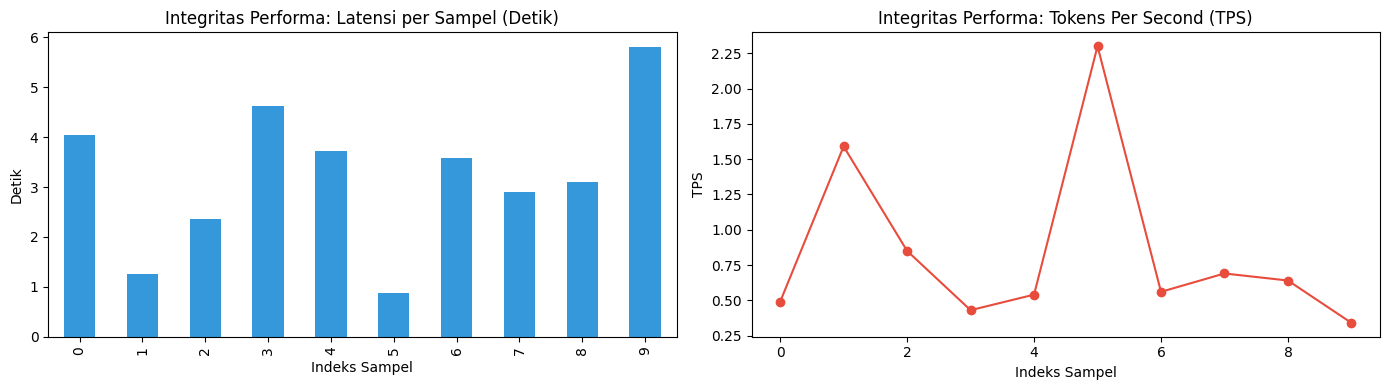

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_results['runtime_sec'].plot(kind='bar', color='#3498db', ax=axes[0])
axes[0].set_title('Integritas Performa: Latensi per Sampel (Detik)')
axes[0].set_xlabel('Indeks Sampel')
axes[0].set_ylabel('Detik')

df_results['tps'].plot(kind='line', marker='o', color='#e74c3c', ax=axes[1])
axes[1].set_title('Integritas Performa: Tokens Per Second (TPS)')
axes[1].set_xlabel('Indeks Sampel')
axes[1].set_ylabel('TPS')

plt.tight_layout()
plt.show()

### **8.3 Metric Aggregation**

In [13]:
invalid_rate = (invalid_count / len(results)) * 100
avg_runtime = df_results["runtime_sec"].mean()
avg_tps = df_results["tps"].mean()

print(
    f"[METRICS] total={len(results)} | "
    f"valid={valid_count} | "
    f"invalid={invalid_count} | "
    f"failure_rate={invalid_rate:.1f}%"
)
print(
    f"[METRICS] avg_runtime={avg_runtime:.2f}s | "
    f"avg_tps={avg_tps:.2f}"
)

assert invalid_rate < 20.0, (
    "[INFERENCE] status=FAILED | "
    "error='parse_failure_rate_exceeded' | "
    f"actual={invalid_rate:.1f}% | "
    "threshold=20.0%"
)

[METRICS] total=10 | valid=10 | invalid=0 | failure_rate=0.0%
[METRICS] avg_runtime=3.23s | avg_tps=0.84
